In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
generation = pd.read_parquet('../cleaned_generation.parquet')
prices = pd.read_parquet('../cleaned_prices.parquet')


df = pd.merge(generation, prices, on=['Start date', 'End date'], how='inner')

price_col = 'Germany/Luxembourg [€/MWh] Calculated resolutions'
features = [
    'Wind onshore [MWh] Calculated resolutions',    
    'Wind offshore [MWh] Calculated resolutions',
    'Photovoltaics [MWh] Calculated resolutions',
    'Fossil gas [MWh] Calculated resolutions'
]


In [14]:
cols_to_clean = features + [price_col]

for col in cols_to_clean:
       df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=False), errors='coerce')


df['Price_Spike'] = (df[price_col] > 100).astype(int)

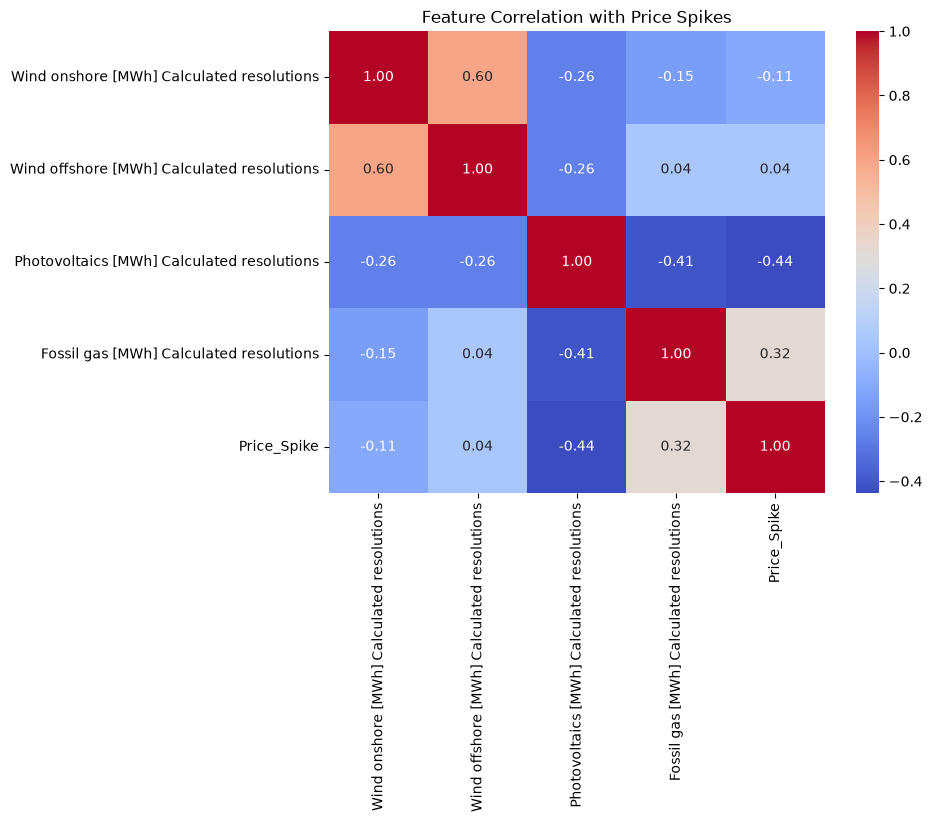

In [15]:
model_data = df[features + ['Price_Spike']].dropna()
X = model_data[features]
y = model_data['Price_Spike']


plt.figure(figsize=(8, 6))
sns.heatmap(X.join(y).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation with Price Spikes")
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}


results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy
    print(f"{name} Accuracy: {accuracy:.4f}")

# 4. Select the best model
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]
print(f"\nBest Model Selected: {best_model_name}")

Logistic Regression Accuracy: 0.9443
Decision Tree Accuracy: 0.9430
Random Forest Accuracy: 0.9580

Best Model Selected: Random Forest


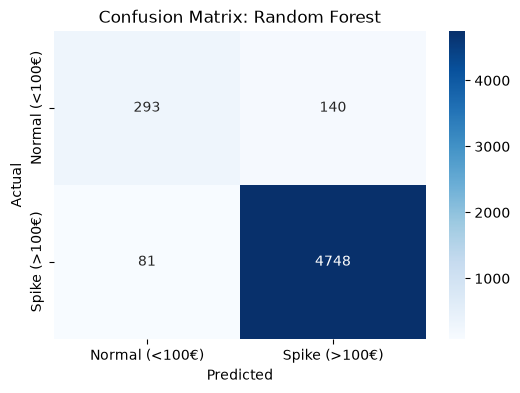

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.68      0.73       433
           1       0.97      0.98      0.98      4829

    accuracy                           0.96      5262
   macro avg       0.88      0.83      0.85      5262
weighted avg       0.96      0.96      0.96      5262



In [18]:
from sklearn.metrics import confusion_matrix, classification_report


y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)


plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal (<100€)', 'Spike (>100€)'], 
            yticklabels=['Normal (<100€)', 'Spike (>100€)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title(f'Confusion Matrix: {best_model_name}')
plt.show()


print("Classification Report:")
print(classification_report(y_test, y_pred))

In [19]:
import joblib

# Export the trained model and feature list to disk
joblib.dump(best_model, 'price_spike_model.pkl')
joblib.dump(features, 'model_features.pkl')
print(f"Successfully exported {best_model_name} and features for deployment.")

Successfully exported Random Forest and features for deployment.
